In [23]:
from typing import TypedDict, List, Dict
from langgraph.graph import StateGraph, START, END
import random

In [24]:
class AgentState(TypedDict):
    name: str
    attempts: int
    guess: List[int]
    lower_bound: int
    upper_bound: int

In [46]:
def greeting_node(state: AgentState) -> AgentState:
    state["name"] = f"Hi, there {state['name']}!"
    state["attempts"] = 0
    return state

def guess_node(state: AgentState) -> AgentState:
    print(f"lower={state['lower_bound']}, upper={state['upper_bound']}, guess={state['guess']}")
    state["guess"].append(random.randint(state["lower_bound"], state["upper_bound"]))
    state["attempts"] += 1
    return state

def should_continue(state: AgentState) -> AgentState:
    if state["guess"][-1] == 17:
        print(f"You guessed correctly {state['guess'][-1]}, exiting...")
        return "exit"
    elif state["attempts"] < 7:
        # print(f"Current attempt is {state['attempts']}, max attempt is 7, continuing...")
        # print(f"Your guess is , try again...")
        
        return "loop"
    else:
        print(f"You reached the max attempts {state['attempts']}, exiting...")
        return "exit"

def update_bounds(state: AgentState) -> AgentState:
    if state["guess"][-1] < 17:
        print(f"Current attempt is {state['attempts']}, Your guess is {state['guess'][-1]}, too low, try again...")
        state["lower_bound"] = state["guess"][-1] + 1
    else:
        print(f"Current attempt is {state['attempts']}, Your guess is {state['guess'][-1]}, too high, try again...")
        state["upper_bound"] = state["guess"][-1] - 1
    return state


In [47]:
graph = StateGraph(AgentState)
graph.add_node("greeting", greeting_node)
graph.add_node("guess", guess_node)
graph.add_node("bounds_node", update_bounds)

graph.add_edge(START, "greeting")
graph.add_edge("greeting", "guess")


graph.add_conditional_edges(
    "guess",
    should_continue,
    {
        "loop": "bounds_node", 
        "exit": END
    } 
)

graph.add_edge("bounds_node", "guess")
graph.add_edge("guess", END)
app = graph.compile()


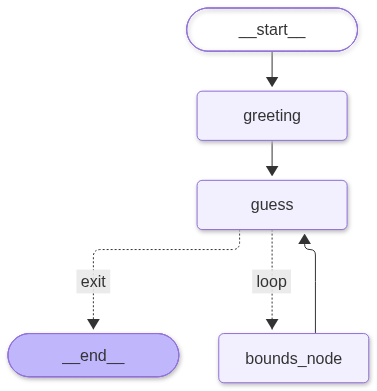

In [27]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [91]:
result = AgentState(name="Alice", guess=[], attempts=0, lower_bound=1, upper_bound=20)
app.invoke(result)

lower=1, upper=20, guess=[]
Current attempt is 1, Your guess is 9, too low, try again...
lower=10, upper=20, guess=[9]
Current attempt is 2, Your guess is 10, too low, try again...
lower=11, upper=20, guess=[9, 10]
Current attempt is 3, Your guess is 11, too low, try again...
lower=12, upper=20, guess=[9, 10, 11]
Current attempt is 4, Your guess is 14, too low, try again...
lower=15, upper=20, guess=[9, 10, 11, 14]
Current attempt is 5, Your guess is 20, too high, try again...
lower=15, upper=19, guess=[9, 10, 11, 14, 20]
Current attempt is 6, Your guess is 15, too low, try again...
lower=16, upper=19, guess=[9, 10, 11, 14, 20, 15]
You reached the max attempts 7, exiting...


{'name': 'Hi, there Alice!',
 'attempts': 7,
 'guess': [9, 10, 11, 14, 20, 15, 19],
 'lower_bound': 16,
 'upper_bound': 19}